In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time
import xarray as xr
import scipy.signal as signal
import glob
import os
import xgboost as xgb
import shap

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score

import matplotlib.gridspec as gridspec
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns

from matplotlib.ticker import MultipleLocator


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
reference_dir = data_dir + '/CHCH_v3_reference/'
reference_mask_dir = reference_dir + 'processed{}/'
model_save_dir = reference_dir + 'models/'

model_mask_dir = data_dir + '/CHCH_v4_model_processed/{}/model_processed_{}/'


### Loading model from file

In [2]:
model_infile = model_save_dir + 'model_001.json'

model = xgb.XGBClassifier();
model.load_model(model_infile)

### Loading training/testing peaks dataset from file

In [35]:
infile = reference_dir + 'peaks_training_df.csv'
peaks_df = pd.read_csv(infile, index_col=[0]) 
print('  <--- ' + infile)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/peaks_training_df.csv


In [36]:
peaks_df = peaks_df.dropna() # removes NaNs (e.g. no temperature data, so bad classification)

eval_days = [
    20210518,
    20210605,
    ]

peaks_df_eval = peaks_df
# peaks_df_eval = peaks_df[peaks_df['date'].isin(eval_days)] ## Filtering to only study the evaluation days

# Removing peaks with unknown and undetermined reference mask classification
peaks_df_eval = peaks_df_eval[peaks_df_eval['unan_target'] == 0]
peaks_df_eval = peaks_df_eval[peaks_df_eval['undet_target'] == 0]
peaks_df_eval = peaks_df_eval.reset_index(drop=True)

# Defining target variables
peaks_df_eval['target'] = peaks_df_eval[['wlwc_target','slwc_target','mpc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target','mpc_target', 'ic_target'], ordered=True)
peaks_df_eval['target_int']= peaks_df_eval['target'].astype(cat_type).cat.codes  

# Select input and target variables
input_vars = [
    'peak_magnitude', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

input = peaks_df_eval[input_vars]
target =  peaks_df_eval['target_int']       

### Applying model to evaluation period

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        79
           1       0.77      0.90      0.83       217
           2       0.17      0.12      0.14        43
           3       0.94      0.86      0.90       285

    accuracy                           0.84       624
   macro avg       0.72      0.72      0.71       624
weighted avg       0.83      0.84      0.83       624

[[0.98734177 0.01265823 0.         0.        ]
 [0.         0.89861751 0.06912442 0.03225806]
 [0.         0.65116279 0.11627907 0.23255814]
 [0.         0.10526316 0.03157895 0.86315789]]


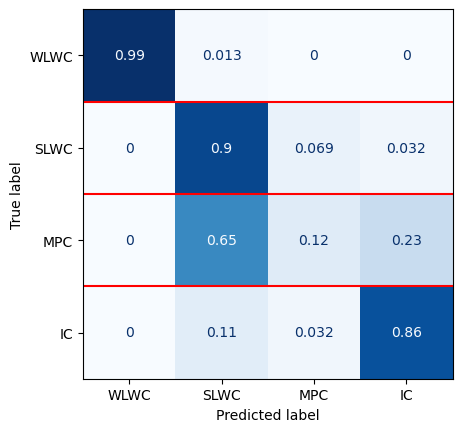

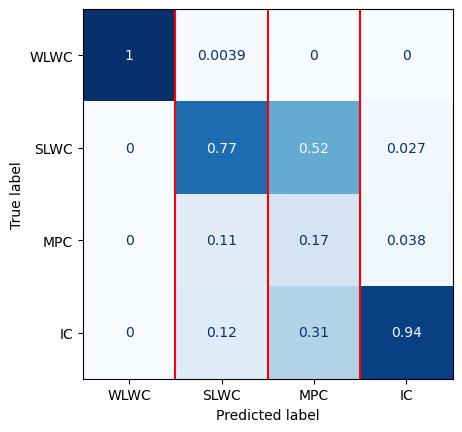

In [5]:
prediction = model.predict(input)

print(classification_report(target, prediction))
print(confusion_matrix(target, prediction,normalize='true'))


class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

### SHAP

In [65]:
explainer = shap.Explainer(model)
shap_values = explainer(input)

In [50]:
np.shape(shap_values)

(36485, 8, 4)

In [8]:
cmap='coolwarm'
c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c_slcc = (0.8,0,0,1)    #SLCC
c_wlcc = (0,0,1)    #WLCC
c_icc = (0.8,0.8,0)    #ICC
c_arr = [c_wlcc,c_icc, c_slcc,c1,]

In [51]:
feat_names = ['Magnitude','Width','Width Height','Prominence','Altitude','n Peaks', 'Peak Order', 'Temperature']
class_names = ['WLWC', 'SLWC', 'MPC', 'IC']

color_lamb = lambda i: c_arr[i]

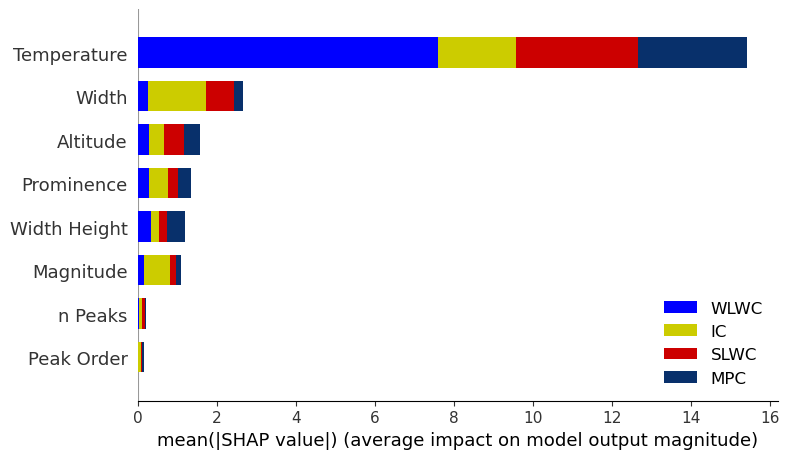

In [52]:
new_shap = [shap_values[:, :, class_ind].values for class_ind in range(shap_values.shape[-1])]

feat_names = ['Magnitude','Width','Width Height','Prominence','Altitude','n Peaks', 'Peak Order', 'Temperature']
class_names = ['WLWC', 'SLWC', 'MPC', 'IC']
color_lamb = lambda i: c_arr[i]

## Works with current version
shap.summary_plot(
    new_shap,
    feature_names=feat_names,
    class_names=class_names,
    plot_type="bar",
    color=color_lamb
)

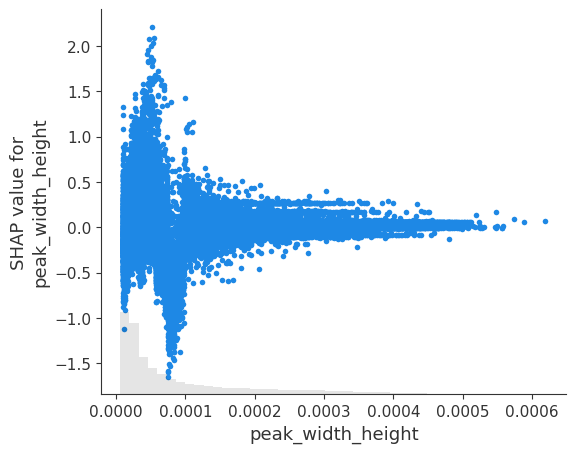

In [83]:
# plt.scatter(shap_values.values,)

# np.shape(shap_values[:,0,0])

shap.plots.scatter(shap_values[:,2,3], cmap=cmap)

/tmp/ipykernel_121943/874757684.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


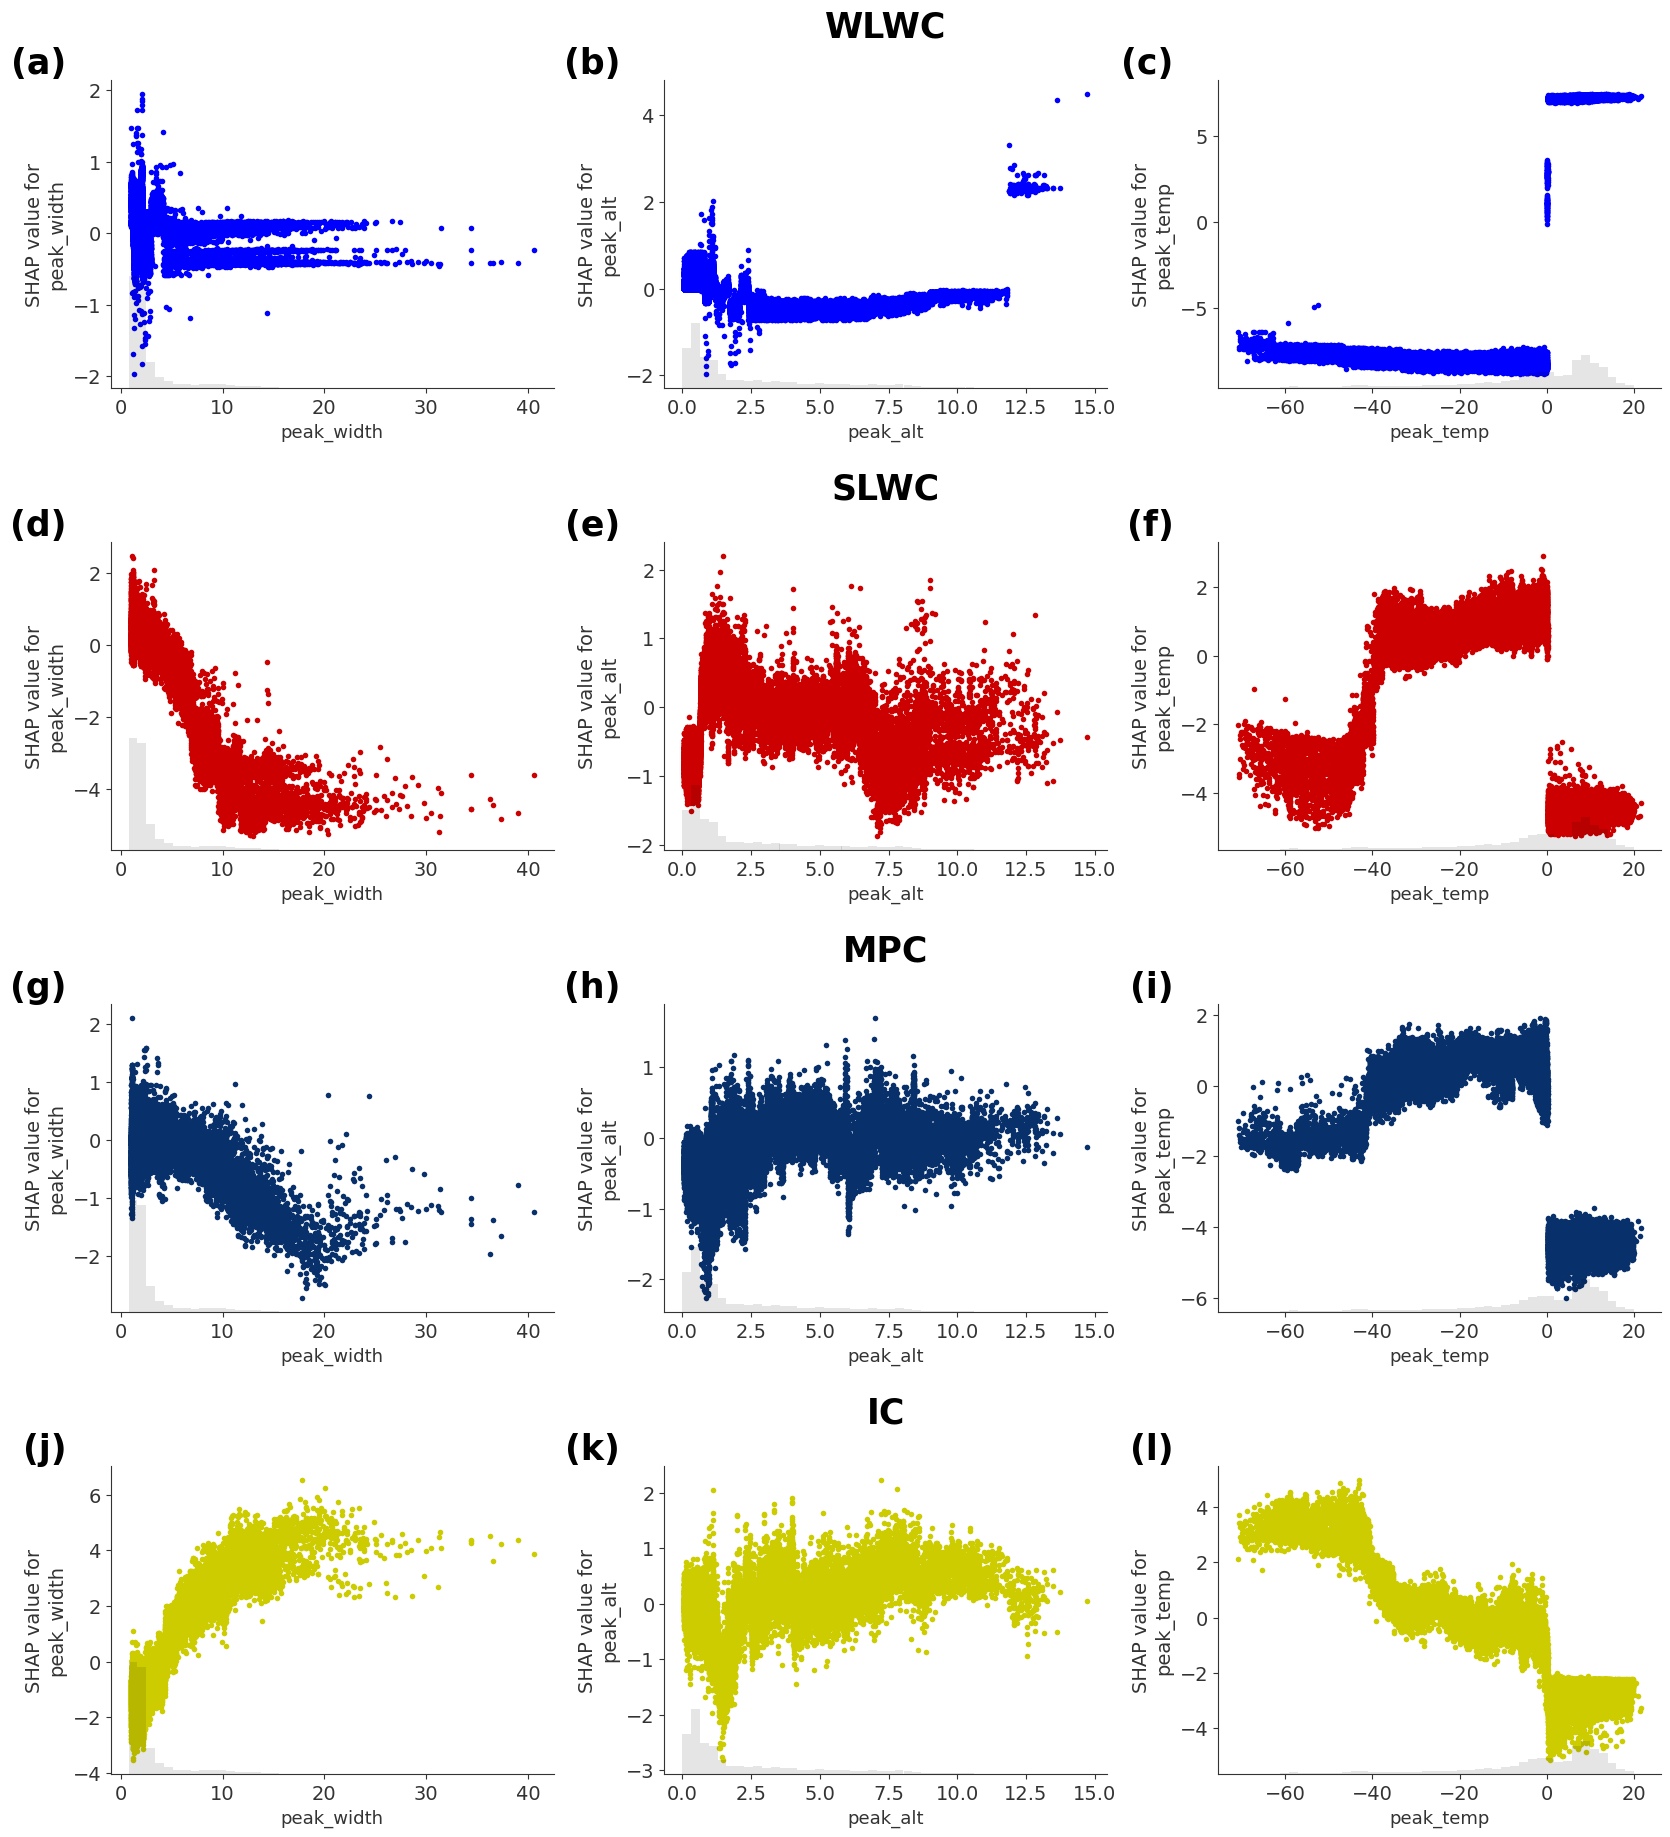

In [96]:
## Makes scatter plots with reduced rows, saves to file

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20,22),gridspec_kw={'hspace':0.5,'wspace':0.25})

c = plt.get_cmap(cmap)
scatter_colour_ICC = (0.8,0.8,0,1)    #Ice/Non-SLW
scatter_colour_LCC = c(0.99)
scatter_colour_SLCC = c(0.01)

c_MPC  = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1) #MPC
c_SLWC = (0.8,0,0,1)     #SLWC
c_WLWC = (0,0,1)    #WLWC
c_IC= (0.8,0.8,0)    #IC
# c5 = (0.7,0.7,0.7) # Unknown


shap.plots.scatter(shap_values[:,1,0], ax=axes[0, 0],show=False,color=c_WLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,1,1], ax=axes[1, 0],show=False,color=c_SLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,1,2], ax=axes[2, 0],show=False,color=c_MPC, cmap=cmap)
shap.plots.scatter(shap_values[:,1,3], ax=axes[3, 0],show=False,color=c_IC  ,cmap=cmap)
# axes[0, 0].set_xlabel('Width',fontsize=15)
# axes[1, 0].set_xlabel('Width',fontsize=15)
# axes[2, 0].set_xlabel('Width',fontsize=15)

shap.plots.scatter(shap_values[:,4,0], ax=axes[0, 1],show=False,color=c_WLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,4,1], ax=axes[1, 1],show=False,color=c_SLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,4,2], ax=axes[2, 1],show=False,color=c_MPC, cmap=cmap)
shap.plots.scatter(shap_values[:,4,3], ax=axes[3, 1],show=False,color=c_IC  ,cmap=cmap)
# axes[0, 1].set_xlabel('Altitude (km)',fontsize=15)
# axes[1, 1].set_xlabel('Altitude (km)',fontsize=15)
# axes[2, 1].set_xlabel('Altitude (km)',fontsize=15)

# # axes[0, 1].ticklabel_format(style='sci', axis='x', scilimits=(0,0))

shap.plots.scatter(shap_values[:,7,0], ax=axes[0, 2],show=False,color=c_WLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,7,1], ax=axes[1, 2],show=False,color=c_SLWC,cmap=cmap)
shap.plots.scatter(shap_values[:,7,2], ax=axes[2, 2],show=False,color=c_MPC, cmap=cmap)
shap.plots.scatter(shap_values[:,7,3], ax=axes[3, 2],show=False,color=c_IC  ,cmap=cmap)
# axes[0, 2].set_xlabel('Temperature ($\\degree$C)',fontsize=15)
# axes[1, 2].set_xlabel('Temperature ($\\degree$C)',fontsize=15)
# axes[2, 2].set_xlabel('Temperature ($\\degree$C)',fontsize=15)



letters='abcdefghijkl'
for i, ax in enumerate(axes.flatten()):
    ax.text(-0.1,1,'({})'.format(letters[i]),fontsize=25,transform=ax.transAxes,ha='right',va='bottom',weight='semibold')
    ax.tick_params(axis='both',which='both',labelsize=14)
    ax.set_ylabel(ax.get_ylabel(),fontsize=14)
    


axes[0, 1].text(0.5,1.12,'WLWC',transform=axes[0, 1].transAxes,ha='center',va='bottom',fontsize=25,weight='semibold')
axes[1,1].text(0.5,1.12,'SLWC',transform=axes[1, 1].transAxes,ha='center',va='bottom',fontsize=25,weight='semibold')
axes[2, 1].text(0.5,1.12,'MPC',transform=axes[2, 1].transAxes,ha='center',va='bottom',fontsize=25,weight='semibold')
axes[3, 1].text(0.5,1.12,'IC',transform=axes[3, 1].transAxes,ha='center',va='bottom',fontsize=25,weight='semibold')


plt.tight_layout()
# plt.savefig('S://atmos_disk//Luke_W_480//MPL_Christchurch_2021//D//SHAP_figs/multi_class_scatters_update.png',dpi=300)

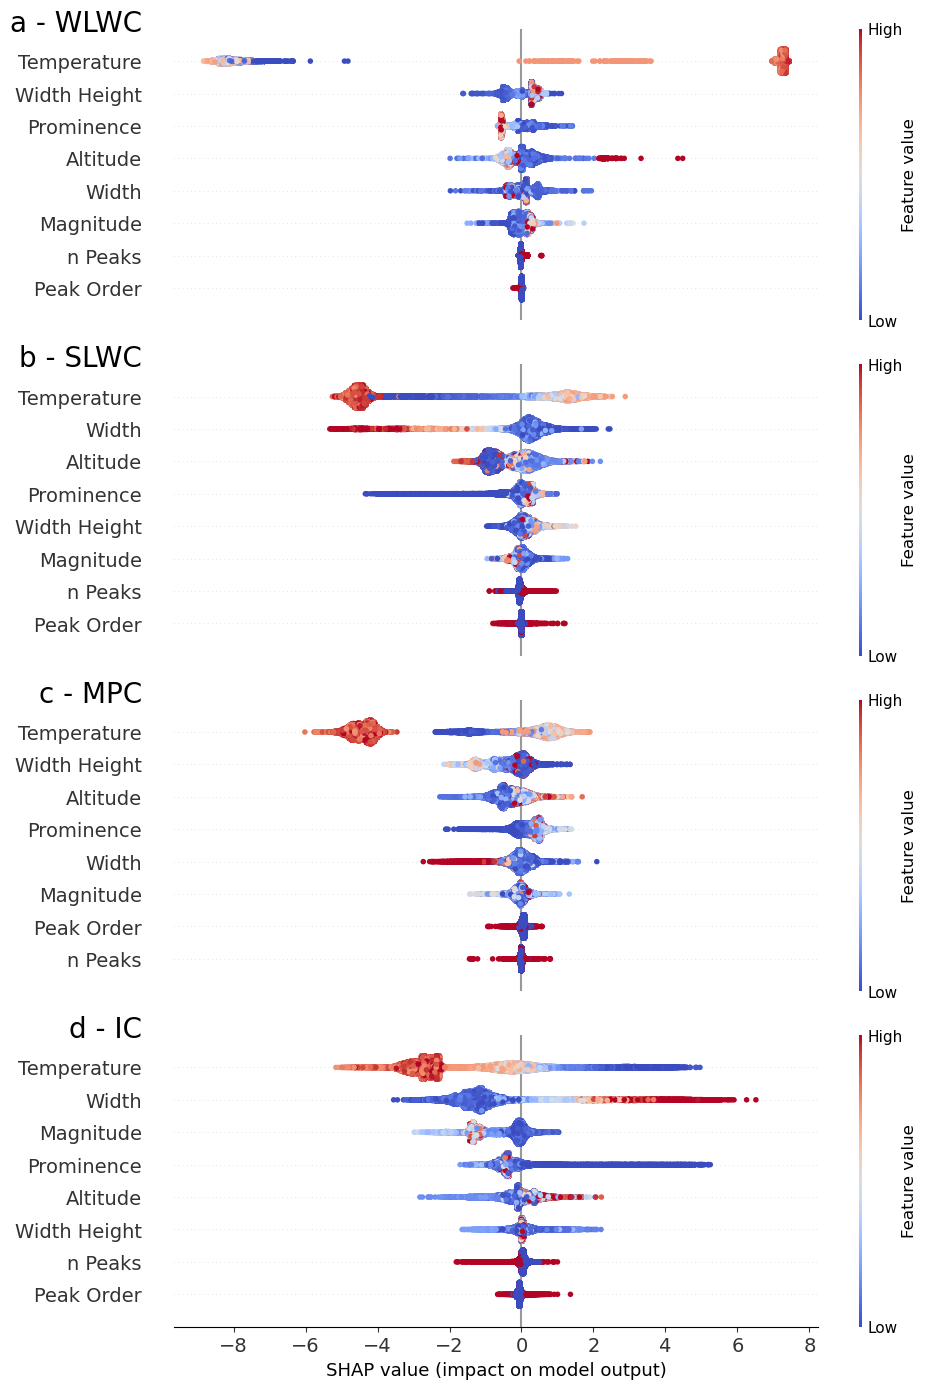

In [79]:
## Beeswarm plot for each class

fig = plt.figure(figsize=(10,14))

ax1 = fig.add_subplot(411)
shap.summary_plot(shap_values[:,:,0].values,input.values,feature_names=feat_names, cmap=cmap,show=False,plot_size=None)

ax2= fig.add_subplot(412,sharex=ax1)
shap.summary_plot(shap_values[:,:,1].values,input.values,feature_names=feat_names, cmap=cmap,show=False,plot_size=None)

ax3= fig.add_subplot(413,sharex=ax1)
shap.summary_plot(shap_values[:,:,2].values,input.values,feature_names=feat_names, cmap=cmap,show=False,plot_size=None)

ax4= fig.add_subplot(414,sharex=ax1)
shap.summary_plot(shap_values[:,:,3].values,input.values,feature_names=feat_names, cmap=cmap,show=False,plot_size=None)

ax1.set_xlabel('')
ax1.spines['bottom'].set_visible(False)
ax1.tick_params(axis='x',bottom=False,labelbottom=False)

ax2.set_xlabel('')
ax2.spines['bottom'].set_visible(False)
ax2.tick_params(axis='x',bottom=False,labelbottom=False)

ax3.set_xlabel('')
ax3.spines['bottom'].set_visible(False)
ax3.tick_params(axis='x',bottom=False,labelbottom=False)

ax4.tick_params(axis='x',labelsize=14)

ax1.text(-0.05,0.97,'a - WLWC',transform=ax1.transAxes,ha='right',va='bottom',fontsize=20)
ax2.text(-0.05,0.97,'b - SLWC',transform=ax2.transAxes,ha='right',va='bottom',fontsize=20)
ax3.text(-0.05,0.97,'c - MPC',transform=ax3.transAxes,ha='right',va='bottom',fontsize=20)
ax4.text(-0.05,0.97,'d - IC',transform=ax4.transAxes,ha='right',va='bottom',fontsize=20)

ax1.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='y', labelsize=14)
ax3.tick_params(axis='y', labelsize=14)
ax4.tick_params(axis='y', labelsize=14)

plt.tight_layout()